### Assignment 1: 
Do personas annotate like people, and does context change them?
- Seed: 3352610
- GitHub: [github.com/AntoLemp/LLM-Persona-Annotation-Context](https://github.com/AntoLemp/LLM-Persona-Annotation-Context)

For Part A, we have to generate 20 questions and rate them. For the seed I chose to use my student ID because it was the simplest random number and it picked understandable sentences so I didn't have to try anything else. 

Below we can see the complete list of sentences:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

items = pd.read_csv('items.csv')
items_rated = pd.read_csv('items_rated.csv')
# Set display options to show all rows and columns in the DataFrame
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

print("All items in the items.csv file:")
display(items)


All items in the items.csv file:


,id,text,rating,label,evidence
0,1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",NaN,NaN,NaN
1,2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,NaN,NaN,NaN
2,3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",NaN,NaN,NaN
3,4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,NaN,NaN,NaN
4,5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.",NaN,NaN,NaN
5,6,"A mistake is ""stupidity""??? That would make you very,very, ......!",NaN,NaN,NaN
6,7,"When the criminal is the son of a former governor, VP candidate, AND reality TV show, publicity hound--it does.",NaN,NaN,NaN
7,8,Or the millions of American white trash criminals with citizenship,NaN,NaN,NaN
8,9,call yourself a kentuckian? daniel boone would've been wearin' that bear's hide.,NaN,NaN,NaN
9,10,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,NaN,NaN,NaN


Below we can see how I rated those sentences, the guidelines I followed were the following:

    Guidelines: how toxic is the item?

    Each item is a short comment from a news-site discussion. Read all of it and give one rating for the whole item, from 1 to 5, by how uncivil, hostile or disrespectful the language is.
    1	Fully civil. Respectful, even if the two sides disagree strongly.
    2	Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.
    3	Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.
    4	Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.
    5	Very toxic. Severe abuse: slurs, threats, harassment, hate.

    1-2 count as civil, 3-5 as toxic. The page shows the label as you rate.
    Rate the tone, not the topic. A controversial subject (abortion, politics, religion) is not toxic by itself, and a calm text defending an ugly view is judged on how it is said.
    A swear word is not automatically toxic: aimed at a person it counts, used for emphasis it counts much less.
    Quoted or reported words count less than words the writer says to someone.
    If several messages differ, let the most toxic part weigh most.
    Use your own judgement: careful readers disagree, and there is no wrong answer. Rate alone, and do not go back to change a rating.
    Give every item a rating. If you rate 3, 4 or 5, also select with the mouse the words that make the text toxic: they are your evidence, and you need at least one to go on. For a 1 or a 2 you only give the rating: the evidence is "not needed"."""

The evidence is mostly curse words, sentences that contain insults or phrases used sarcasticly which still count as toxic in my mind.


In [2]:
print("All items in the items_rated.csv file:")
display(items_rated)

All items in the items_rated.csv file:


,id,text,rating,label,evidence
0,1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",2,civil,not needed
1,2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,5,toxic,deserve death || vile animals
2,3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed
3,4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,4,toxic,Bullshit Story || laughing their butts off || idiot
4,5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.",1,civil,not needed
5,6,"A mistake is ""stupidity""??? That would make you very,very, ......!",3,toxic,"stupidity || make you very,very, ......!"
6,7,"When the criminal is the son of a former governor, VP candidate, AND reality TV show, publicity hound--it does.",1,civil,not needed
7,8,Or the millions of American white trash criminals with citizenship,4,toxic,white trash criminals
8,9,call yourself a kentuckian? daniel boone would've been wearin' that bear's hide.,1,civil,not needed
9,10,Wow. Kind of leaves one breathless after previously only hearing about mailbox theft.,1,civil,not needed


Now we are going to create the histogram and a boxplot of our ratings

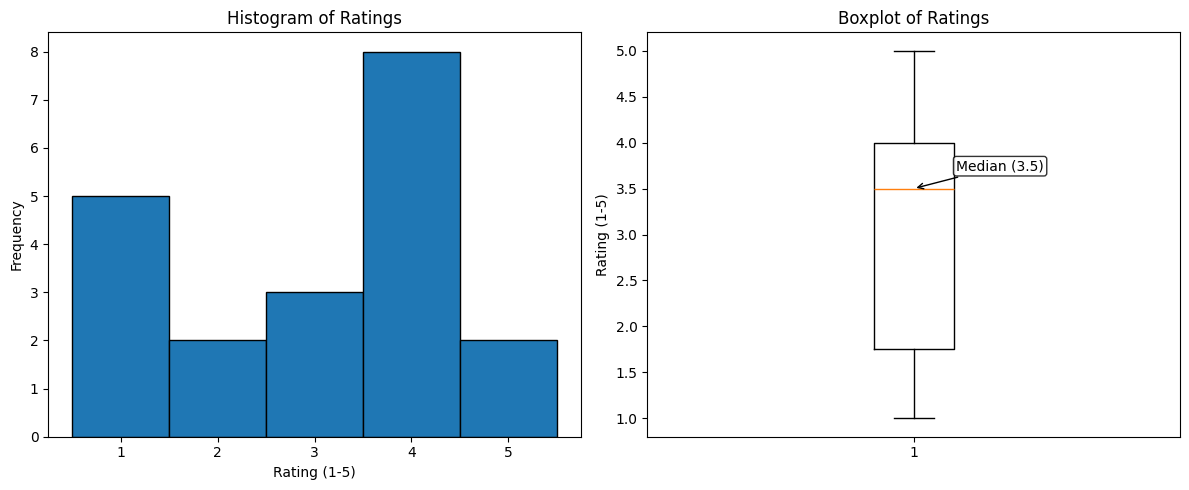

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(items_rated['rating'].dropna(), bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor='black')
axes[0].set_title('Histogram of Ratings')
axes[0].set_xlabel('Rating (1-5)')
axes[0].set_ylabel('Frequency')

# Boxplot
bp = axes[1].boxplot(items_rated['rating'].dropna())
axes[1].set_title('Boxplot of Ratings')
median = bp['medians'][0].get_ydata()[0]
axes[1].set_ylabel('Rating (1-5)')
axes[1].annotate(
    f'Median ({median:g})',
    xy=(1, median),
    xytext=(1.08, median + 0.2),
    arrowprops=dict(arrowstyle='->'),
    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.8)
)


plt.tight_layout()
plt.show()

### Part B:
As we can see from the histogram our sentences span the entire scale, we can somewhat tell we are leaning towards the toxic side  but can't say by how much right away.

From the boxplot we can clearly see that we lean slightly towards the toxic side (if we consider 3 to be the borderline) with a median of 3.5

In [4]:
%pip install -q syndisco

In [5]:
import torch
import syndisco
import random
import re
from dotenv import load_dotenv
import os
load_dotenv()
api_key = os.getenv('HF_TOKEN')
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


I chose to combine T4 GPU Colab with Qwen2.5 with 3B parameters, even though the answers are mostly somewhat similar and sometimes give results that we wouldn't expect with a specific background, at our level they are the best possible because of our limited compute units and the time it takes for the whole project to run (around 30min). Tried using Qwen2.5 with 7B parameters but it took around an hour (lost the results because my colab session got timed out).

In [6]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",   # which model to download
    name="qwen",                                         # a name for the logs
    max_out_tokens=80,                                   # longest answer: enough for a short reply
    generation_kwargs={"repetition_penalty": 1.1},       # avoids repeating the previous comment
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Because I wanted this to be fast but still get different opinion, I designed it in a way that we have people from all different ages group, for the youth we have:  
* An 18year old male closed-minded student
* A 25 year old female friendly software engineer
* A 30 year old non-binary open-minded artist.

With these 3 different personalities we should be able to get comments from different perspectives of the youth.

On the older side we have: 
* A 54 year old female conservative truck driver
* A 75 year old male blunt retiree

With these 2 different personalities we are trying to generate comments that are more conservative and maybe try to justify some of the toxic comments.

For the context, we simply ask the personas to be commentators in a disucssion thread. They are instructed to make one short comment each (Tried to get them to be able to reply to their someones comment on theirs, but I couldn't manage to get syndisco.RandomTurnManager(users,p_respond=0.5) to work since I got an error code). The instructions also state how it should react so they don't go off script or find their own comment to be the best one.

In [7]:
PERSONAS = [{
    "username": "Alice", "age": 25, "gender": "female", "personality": "[friendly, confident], job: software engineer"
}, {
    "username": "Bob", "age": 18, "gender": "male", "personality": "[introverted, stubborn, closed-minded], job: student"
}, {
    "username": "Charlie", "age": 30, "gender": "non-binary", "personality": "[warm, open-minded], job: artist"
}, {
    "username": "Diana", "age": 54, "gender": "female", "personality": "[grumpy, practical, conservative], job: truck driver"
}, {
    "username": "Ethan", "age": 75, "gender": "male", "personality": "[blunt, spontaneous], job: retiree"
}]

CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not react to your own personas comments, do not mention that you are role-playing,"
    "do not mention that you are an AI, and never answer with an apology."
)

We chose to use 3 users per discussion and the total lenght of the conversation must be 4 replies. This way it stays short and the personas don't start complementing eachothers replies (we have a small model so we mostly get the same replies).

In [8]:
rng = random.Random(3352610)
conversations = {}

for i, r in items.iterrows():
    item_text = r['text']
    users = [
        syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
        for p in rng.sample(PERSONAS, 3)
    ]
    # 2. set up the discussion
    discussion = syndisco.Discussion(
        next_turn_manager=syndisco.RandomTurnManager(users),  # who speaks next
        users=users,
        conv_len=4,                          # number of replies the model writes
        seed_opinions=[item_text],                   # the text itself opens the thread...
        seed_opinion_usernames=["OriginalPoster"],            # ...as if written by this user
    )
    # 3. run it and keep the log (the list of comments)
    discussion.begin(verbose=False)
    conversations[i] = discussion.get_logs()
print("done")


/usr/local/lib/python3.13/dist-packages/syndisco/turn_manager.py:163: UserWarning: 
                p_respond has been set to 0, which disables responding
                altogether. In that case, it may be better to use the
                RandomTurnManager class instead.
                
  warnings.warn(


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

... (32 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

done


Here we can see the actual discussions.

Some notable discussions (for how they don't understand the context) are number 13 and 15 were the personas don't understand the sarcastic tone of those comments and answer seriously. We can also see that the commentators mostly agree with eachother even if they have different personas, if one of them starts with a certain type of comment (for example a positive one) the rest most of the time will simply agree and repeat something similar, without adding anything useful most of the time. 

In [9]:
def as_text(logs):
    # one line per comment: "name: text"
    return "\n".join(f'{e["name"]}: {e["text"]}' for e in logs)

for i, logs in conversations.items():
    print(f"--- conversation {i} ---")
    print(as_text(logs), "\n")

--- conversation 0 ---
OriginalPoster: "if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves" Honolulu city government, putting the funk back into dysfunktional
Alice: I couldn't have said it better myself! Our current political climate truly does feel like we're going backwards.
Ethan: "Absolutely spot on, OriginalPoster. It's clear we've lost sight of what makes governance effective."
Charlie: "Echoing your sentiments, OriginalPoster—our political landscape really does seem to be regressing."
Ethan: "Agreed wholeheartedly, OriginalPoster. The state of politics right now just doesn't make sense." 

--- conversation 1 ---
OriginalPoster: People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.
Ethan: "Absolutely right about those abusing 

In [10]:
import json
with open("generated.jsonl", "w", encoding="utf-8") as f:
    for i, logs in conversations.items():
        entry = {"id": i, "conversation": [{"name": e["name"], "text": e["text"]} for e in logs]}
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")
print("saved generated.jsonl")

saved generated.jsonl


Here I created a $2\times2\times2$ grid for the new personalities. Each personality must be either female or male, have conservative or socialist political views and be of high school or college education. We chose such a small grids because when we experimented with bigger ones the ratings took way too long. These should be good enough to make different characters with different views on the comments we are about to present them.

In [16]:
import itertools
genders = ["female", "male"]
political_views = ["conservative", "socialist"]
educations = ["high school", "college"]

personas = []
for gender, political_view, education in itertools.product(genders, political_views, educations):
    persona = {
        "gender": gender,
        "political_view": political_view,
        "education": education
    }
    personas.append(persona)

annotators = personas + [None]


In [12]:
import re
import pandas as pd

RATING_INSTRUCTIONS = (
    "Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). "
    "If you rate 3, 4, or 5, quote the exact toxic words. "
    "Reply ONLY in this format: <number> | <words>. "
    "Example for civil: 1 | not needed\n"
    "Example for toxic: 4 | you are stupid"
)
model.max_out_tokens = 60

def rate(text, conversation=None, persona=None):
    context = "You are annotating comments from an online discussion."
    if conversation:
        context += " Before you rate, read the conversation that people had about the comment:\n" + conversation

    name = "baseline" if persona is None else ", ".join(persona.values())
    annotator = syndisco.Actor(
        model=model, persona=persona, context=context, instructions=RATING_INSTRUCTIONS,
        is_annotator=True, name=name,
    )

    logs = syndisco.Logs()
    logs.append("comment", text)

    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    
    log_entry = job.get_logs()[0]
    raw_answer = log_entry["text"].strip()
    prompt = log_entry.get("prompt", "")

    rating = None
    evidence = "not needed"
    
    match = re.search(r"([1-5])", raw_answer)
    if match:
        rating = int(match.group(1))
        if rating >= 3:
            if "|" in raw_answer:
                evidence = raw_answer.split("|", 1)[1].strip()
            else:
                evidence = raw_answer[match.end():].strip()
            if not evidence or evidence.lower() in ["none", "not needed"]:
                evidence = "missing"

    label = "toxic" if rating and rating >= 3 else ("civil" if rating else None)

    # Returning raw_answer prevents the KeyError
    return {
        "raw_answer": raw_answer, 
        "rating": rating,
        "evidence": evidence,
        "label": label,
        "prompt": prompt
    }

# Test on just the very first item
test_item = items.iloc[0]['text']
print(f"Testing on: {test_item}\n")

res = rate(test_item, persona=annotators[0])
print("--- TEST RESULT ---")
print(f"Raw Model Output: {res['raw_answer']}")
print(f"Parsed Rating: {res['rating']}")
print(f"Parsed Evidence: {res['evidence']}")

Testing on: "if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves" Honolulu city government, putting the funk back into dysfunktional



  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- TEST RESULT ---
Raw Model Output: 4 | dysfunction | incompetent
Parsed Rating: 4
Parsed Evidence: dysfunction | incompetent


In [13]:
results_no_context = []
results_with_context = []

print("Running annotations across the persona grid... This will take a while.")

for persona in annotators:
    name = "baseline" if persona is None else ", ".join(persona.values())
    print(f"Annotating as: {name}")
    
    for i, r in items.iterrows():
        item_text = r['text']
        item_id = r['id']
        
        # E. No context run
        res_nc = rate(item_text, persona=persona)
        results_no_context.append({
            "annotator": name,
            "id": item_id,
            "text": item_text,
            "raw_answer": res_nc["raw_answer"],
            "rating": res_nc["rating"],
            "label": res_nc["label"],
            "evidence": res_nc["evidence"],
            "prompt": res_nc["prompt"]
        })
        
        # D. With context run
        conv_text = as_text(conversations[i])
        res_wc = rate(item_text, conversation=conv_text, persona=persona)
        results_with_context.append({
            "annotator": name,
            "id": item_id,
            "text": item_text,
            "raw_answer": res_wc["raw_answer"],
            "rating": res_wc["rating"],
            "label": res_wc["label"],
            "evidence": res_wc["evidence"],
            "prompt": res_wc["prompt"]
        })

df_no_context = pd.DataFrame(results_no_context)
df_with_context = pd.DataFrame(results_with_context)

print("Done generating annotations!")

Running annotations across the persona grid... This will take a while.
Annotating as: female, conservative, high school


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

... (720 outputs left out)

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Done generating annotations!


This took approximately 29min to complete.

In [14]:
# The assignment requires displaying the full tables for both conditions (D and E)
# with columns: id, text, rating, label, evidence, annotator, and prompt.

print("--- Part E: Annotations WITHOUT Context ---")
display(df_no_context)

print("\n--- Part D: Annotations WITH Context ---")
display(df_with_context)

# Save the results to CSV files for your records
df_no_context.to_csv("lab_results_no_context.csv", index=False)
df_with_context.to_csv("lab_results_with_context.csv", index=False)

--- Part E: Annotations WITHOUT Context ---


,annotator,id,text,raw_answer,rating,label,evidence,prompt
0,"female, conservative, high school",1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",4 | dysfunction | incompetent,4,toxic,dysfunction | incompetent,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
1,"female, conservative, high school",2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,4 | people are some of the most vile animals out there and deserve death,4,toxic,people are some of the most vile animals out there and deserve death,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
2,"female, conservative, high school",3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.","2 | No, not in 'other' words, in precisely the words I wrote.",2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
3,"female, conservative, high school",4,Who wrote this Bullshit Story? The Chomorro's of Guam are laughing their butts off at that idiot in N. Korea,2 | Bullshit Story \n2 | idiot,2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
4,"female, conservative, high school",5,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.","1 | I still don’t believe Candace’s story, or HughRG’s. They’re just making stuff up.",1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
5,"female, conservative, high school",6,"A mistake is ""stupi


--- Part D: Annotations WITH Context ---


,annotator,id,text,raw_answer,rating,label,evidence,prompt
0,"female, conservative, high school",1,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",1 | not needed,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: \""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves\"" Honolulu city government, putting the funk back into dysfunktional\nAlice: I couldn't have said it better myself! Our current political climate truly does feel like we're going backwards.\nEthan: \""Absolutely spot on, OriginalPoster. It's clear we've lost sight of what makes governance effective.\""\nCharlie: \""Echoing your sentiments, OriginalPoster\u2014our political landscape really does seem to be regressing.\""\nEthan: \""Agreed wholeheartedly, OriginalPoster. The state of politics right now just doesn't make sense.\"""", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
1,"female, conservative, high school",2,People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.,5 | People who abuse their authority are some of the most vile animals out there and deserve death. Too bad criminal charge aren't being brought in addition to civil suits.,5,toxic,People who abuse their authority are some of the most vile animals out there and deserve death. Too bad criminal charge aren't being brought in addition to civil suits.,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: People who abuse their authority are some of the most vile animals out there and deserve death. Of course there is a chance the inmates are lying or not being entirely truthful. Too bad criminal charge aren't being brought in addition to civil suits.\nEthan: \""Absolutely right about those abusing power. But bringing charges isn't always enough; sometimes it takes more than just legal action.\""\nBob: \""Agreed, Ethan. Sometimes, going beyond just legal actions can make a bigger impact.\""\nDiana: \""Totally agree, Bob. It's crucial to go beyond just legal actions when dealing with such cases.\""\nBob: \""Indeed, taking additional steps like community service or rehabilitation programs can really help.\"""", ""instructions"": ""Rate the toxicity of the comment from 1 (fully civil) to 5 (very toxic). If you rate 3, 4, or 5, quote the exact toxic words. Reply ONLY in this format: <number> | <words>. Example for civil: 1 | not needed\nExample for toxic: 4 | you are stupid"", ""type"": ""annotator"", ""persona"": {""gender"": ""female"", ""political_view"": ""conservative"", ""education"": ""high school""}}"
2,"female, conservative, high school",3,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",1 | not needed,1,civil,not needed,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supporte

1 & 2. YOU VS. ANNOTATORS (Without & With Context)


,Annotator,Numerical Agree (No Context),Categorical Agree (No Context),Numerical Agree (With Context),Categorical Agree (With Context)
2,"female, socialist, high school",0.60,0.85,0.35,0.85
7,"male, socialist, college",0.60,0.85,0.30,0.85
3,"female, socialist, college",0.60,0.85,0.35,0.85
6,"male, socialist, high school",0.60,0.85,0.35,0.85
5,"male, conservative, college",0.55,0.85,0.30,0.80
0,"female, conservative, high school",0.50,0.80,0.35,0.85
1,"female, conservative, college",0.50,0.85,0.30,0.85
4,"male, conservative, high school",0.50,0.85,0.35,0.85
8,baseline,0.50,0.80,0.30,0.75



3. ANNOTATORS: NO CONTEXT VS. WITH CONTEXT


,Annotator,Numerical Agree (NC vs WC),Categorical Agree (NC vs WC)
3,"female, socialist, college",0.15,0.90
2,"female, socialist, high school",0.15,0.90
6,"male, socialist, high school",0.15,0.90
7,"male, socialist, college",0.15,0.90
0,"female, conservative, high school",0.20,0.85
1,"female, conservative, college",0.25,0.90
5,"male, conservative, college",0.25,0.95
4,"male, conservative, high school",0.25,0.90
8,baseline,0.30,0.95



4. PERSONA VS. PERSONA AGREEMENT (Numerical 1-5)


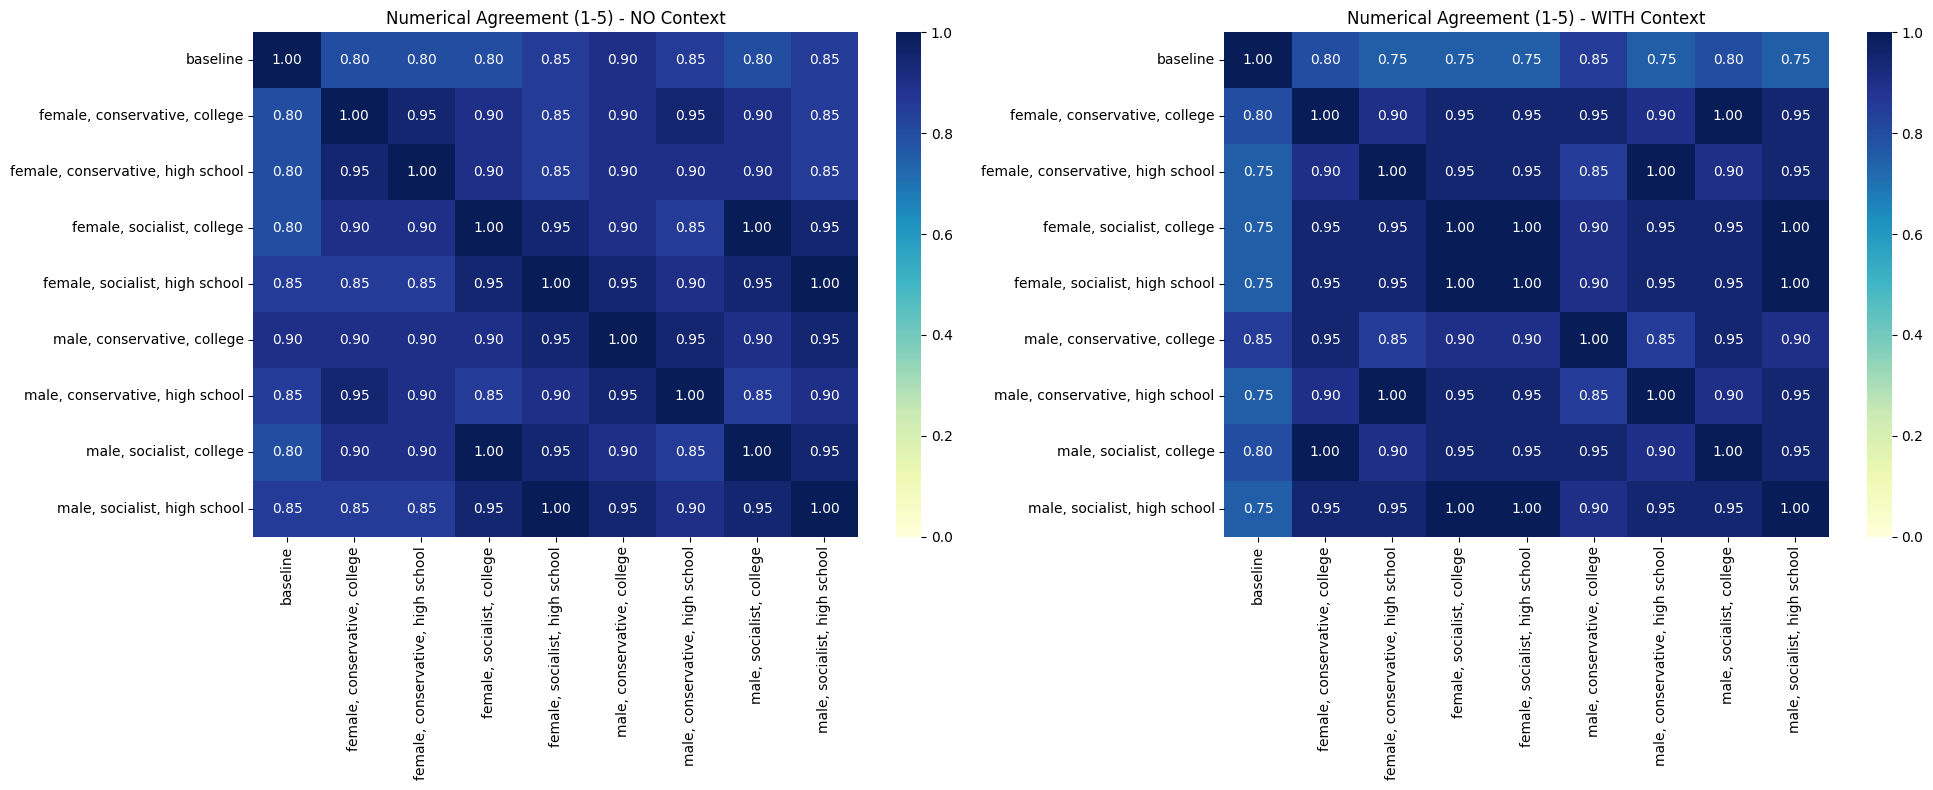


DIMENSION ANALYSIS: Which trait separates them the most?
Average numerical agreement when personas DIFFER by dimension (No Context):
Politics     0.887500
Gender       0.915625
Education    0.915625
dtype: float64

Average numerical agreement when personas DIFFER by dimension (With Context):
Education    0.92500
Politics     0.93750
Gender       0.94375
dtype: float64

Average pairwise numerical agreement (No Context): 0.894
Average pairwise numerical agreement (With Context): 0.903

--- Extremes: Numerical Agreement (No Context) ---
Highest agreement (Smallest diff): 'female, socialist, college' & 'male, socialist, college' at 1.00
Lowest agreement (Biggest diff): 'baseline' & 'female, conservative, college' at 0.80

--- Extremes: Numerical Agreement (With Context) ---
Highest agreement (Smallest diff): 'female, conservative, college' & 'male, socialist, college' at 1.00
Lowest agreement (Biggest diff): 'baseline' & 'female, conservative, high school' at 0.75


In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare your ratings for comparison
your_ratings = items_rated[['id', 'rating', 'label']].rename(
    columns={'rating': 'your_rating', 'label': 'your_label'}
)

# Merge your ratings into the model outputs
df_nc = df_no_context.merge(your_ratings, on='id')
df_wc = df_with_context.merge(your_ratings, on='id')

def calc_agreement(df, col1, col2):
    return (df[col1] == df[col2]).mean()

print("1 & 2. YOU VS. ANNOTATORS (Without & With Context)")
results_you_vs_model = []

for annotator in df_nc['annotator'].unique():
    sub_nc = df_nc[df_nc['annotator'] == annotator]
    sub_wc = df_wc[df_wc['annotator'] == annotator]
    
    results_you_vs_model.append({
        'Annotator': annotator,
        'Numerical Agree (No Context)': calc_agreement(sub_nc, 'rating', 'your_rating'),
        'Categorical Agree (No Context)': calc_agreement(sub_nc, 'label', 'your_label'),
        'Numerical Agree (With Context)': calc_agreement(sub_wc, 'rating', 'your_rating'),
        'Categorical Agree (With Context)': calc_agreement(sub_wc, 'label', 'your_label')
    })

# Sorting by Numerical Agreement instead of Categorical
df_you_vs_model = pd.DataFrame(results_you_vs_model).sort_values(by='Numerical Agree (No Context)', ascending=False)
display(df_you_vs_model)


print("\n3. ANNOTATORS: NO CONTEXT VS. WITH CONTEXT")
df_context_shift = df_nc[['annotator', 'id', 'rating', 'label']].merge(
    df_wc[['annotator', 'id', 'rating', 'label']], 
    on=['annotator', 'id'], 
    suffixes=('_nc', '_wc')
)

shift_results = []
for annotator in df_context_shift['annotator'].unique():
    sub = df_context_shift[df_context_shift['annotator'] == annotator]
    shift_results.append({
        'Annotator': annotator,
        'Numerical Agree (NC vs WC)': calc_agreement(sub, 'rating_nc', 'rating_wc'),
        'Categorical Agree (NC vs WC)': calc_agreement(sub, 'label_nc', 'label_wc')
    })

display(pd.DataFrame(shift_results).sort_values(by='Numerical Agree (NC vs WC)'))


print("\n4. PERSONA VS. PERSONA AGREEMENT (Numerical 1-5)")
# Pivot tables now use 'rating' (1-5) instead of 'label'
pivot_nc = df_nc.pivot(index='id', columns='annotator', values='rating')
pivot_wc = df_wc.pivot(index='id', columns='annotator', values='rating')

def pairwise_numerical_agreement(pivot_df):
    cols = pivot_df.columns
    matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for c1 in cols:
        for c2 in cols:
            matrix.loc[c1, c2] = (pivot_df[c1] == pivot_df[c2]).mean()
    return matrix

matrix_nc = pairwise_numerical_agreement(pivot_nc)
matrix_wc = pairwise_numerical_agreement(pivot_wc)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(matrix_nc, annot=True, cmap="YlGnBu", vmin=0, vmax=1, ax=axes[0], fmt=".2f")
axes[0].set_title('Numerical Agreement (1-5) - NO Context')
axes[0].set_ylabel('')
axes[0].set_xlabel('')

sns.heatmap(matrix_wc, annot=True, cmap="YlGnBu", vmin=0, vmax=1, ax=axes[1], fmt=".2f")
axes[1].set_title('Numerical Agreement (1-5) - WITH Context')
axes[1].set_ylabel('')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

# Analyze which dimension separates the personas the most
def evaluate_dimensions(matrix):
    # Remove the baseline since it has no dimensions
    personas = [p for p in matrix.columns if p != 'baseline']
    mat = matrix.loc[personas, personas]
    
    # We assume your annotator strings are formatted as "gender, politics, education"
    # Example: "female, liberal, college"
    dimensions = ['Gender', 'Politics', 'Education']
    results = {}
    
    for dim_idx, dim_name in enumerate(dimensions):
        diff_agreements = []
        for p1 in personas:
            for p2 in personas:
                # Extract the specific trait for this dimension (e.g., 'female' vs 'male')
                val1 = p1.split(', ')[dim_idx]
                val2 = p2.split(', ')[dim_idx]
                
                # If the trait is different, record their agreement
                if val1 != val2:
                    diff_agreements.append(mat.loc[p1, p2])
                    
        # Average the agreement for all pairs that differ on this dimension
        results[dim_name] = np.mean(diff_agreements)
        
    return pd.Series(results).sort_values()

print("\nDIMENSION ANALYSIS: Which trait separates them the most?")
print("Average numerical agreement when personas DIFFER by dimension (No Context):")
print(evaluate_dimensions(matrix_nc))

print("\nAverage numerical agreement when personas DIFFER by dimension (With Context):")
print(evaluate_dimensions(matrix_wc))

# Calculate average pairwise agreement
avg_nc = matrix_nc.values[np.triu_indices_from(matrix_nc, k=1)].mean()
avg_wc = matrix_wc.values[np.triu_indices_from(matrix_wc, k=1)].mean()
print(f"\nAverage pairwise numerical agreement (No Context): {avg_nc:.3f}")
print(f"Average pairwise numerical agreement (With Context): {avg_wc:.3f}")

# Find biggest and smallest numerical differences
def get_min_max_agreement(matrix):
    mat_nan = matrix.copy()
    np.fill_diagonal(mat_nan.values, np.nan)
    
    min_val = mat_nan.min().min()
    min_idx = mat_nan.stack().idxmin() 
    
    max_val = mat_nan.max().max()
    max_idx = mat_nan.stack().idxmax()
    
    return (min_idx, min_val), (max_idx, max_val)

min_nc, max_nc = get_min_max_agreement(matrix_nc)
min_wc, max_wc = get_min_max_agreement(matrix_wc)

print("\n--- Extremes: Numerical Agreement (No Context) ---")
print(f"Highest agreement (Smallest diff): '{max_nc[0][0]}' & '{max_nc[0][1]}' at {max_nc[1]:.2f}")
print(f"Lowest agreement (Biggest diff): '{min_nc[0][0]}' & '{min_nc[0][1]}' at {min_nc[1]:.2f}")

print("\n--- Extremes: Numerical Agreement (With Context) ---")
print(f"Highest agreement (Smallest diff): '{max_wc[0][0]}' & '{max_wc[0][1]}' at {max_wc[1]:.2f}")
print(f"Lowest agreement (Biggest diff): '{min_wc[0][0]}' & '{min_wc[0][1]}' at {min_wc[1]:.2f}")